# Scoring Prediction Model

**Uses `marts.play_features` table**

In [29]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# modeling (scikit-learn)
import joblib                                                   # save / load the trained model
from sklearn.linear_model import LogisticRegression             # baseline model
from sklearn.ensemble import HistGradientBoostingClassifier     # main model: handles NULLs, monotonic constraints
from sklearn.pipeline import (make_pipeline, Pipeline)
from sklearn.impute import SimpleImputer                        # fill NULLs for the baseline (logistic can't take them)
from sklearn.preprocessing import StandardScaler
from sklearn.isotonic import IsotonicRegression                 # calibrate probabilities on the validation season
from sklearn.calibration import calibration_curve, CalibrationDisplay
from sklearn.metrics import log_loss, brier_score_loss, roc_auc_score
from sklearn.model_selection import train_test_split

# shared project code (src/cfb): paths, database connection, read_query()
from cfb.config import ROOT, SQL_ANALYSIS_DIR
from cfb.db import engine, read_query



In [30]:
df = pd.read_sql(
    "SELECT * FROM marts.play_features WHERE season >= 2014",
    engine,
)
df.head()

,play_id,drive_id,game_id,season,week,season_type,offense,defense,down,distance,...,off_ppd_szn,def_ppa_szn,def_ppd_szn,off_elo,def_elo,offense_spread,off_games_prior,def_games_prior,drive_scored,drive_result
0,401286303101884106,4012863033,401286303,2021,10,regular,Massachusetts,Rhode Island,1,10,...,1.25,NaN,NaN,528.0,NaN,-2.5,8.0,0.0,1,TD
1,401286303101884107,4012863033,401286303,2021,10,regular,Massachusetts,Rhode Island,2,6,...,1.25,NaN,NaN,528.0,NaN,-2.5,8.0,0.0,1,TD
2,401286303101884108,4012863033,401286303,2021,10,regular,Massachusetts,Rhode Island,2,3,...,1.25,NaN,NaN,528.0,NaN,-2.5,8.0,0.0,1,TD
3,401286303101884109,4012863033,401286303,2021,10,regular,Massachusetts,Rhode Island,1,10,...,1.25,NaN,NaN,528.0,NaN,-2.5,8.0,0.0,1,TD
4,401286303101884110,4012863033,401286303,2021,10,regular,Massachusetts,Rhode Island,2,9,...,1.25,NaN,NaN,528.0,NaN,-2.5,8.0,0.0,1,TD


In [31]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1466328 entries, 0 to 1466327
Data columns (total 35 columns):
 #   Column              Non-Null Count    Dtype  
---  ------              --------------    -----  
 0   play_id             1466328 non-null  str    
 1   drive_id            1466328 non-null  str    
 2   game_id             1466328 non-null  int64  
 3   season              1466328 non-null  int64  
 4   week                1466328 non-null  int64  
 5   season_type         1466328 non-null  str    
 6   offense             1466328 non-null  str    
 7   defense             1466328 non-null  str    
 8   down                1466328 non-null  int64  
 9   distance            1466328 non-null  int64  
 10  yards_to_goal       1466328 non-null  int64  
 11  period              1466328 non-null  int64  
 12  sec_left_in_half    1462051 non-null  float64
 13  is_overtime         1466328 non-null  bool   
 14  score_margin        1466328 non-null  int64  
 15  is_home             146632

In [32]:
# ---------- column roles ----------
# identifiers: for joining and splitting train/test by season, never features
key_columns = ['play_id', 'drive_id', 'game_id', 'season', 'week', 'season_type', 'offense', 'defense']

target = 'drive_scored'

# the drive's outcome: it gives away the answer, so never a feature
leak_columns = ['drive_result']

# continuous numeric features
numeric_columns = [
    # situation at the snap
    'distance', 'yards_to_goal', 'sec_left_in_half', 'score_margin',
    # drive so far (earlier snaps only)
    'drive_play_num', 'drive_yards_so_far', 'drive_ppa_so_far', 'drive_start_ytg',
    # team strength (season to date, prior games only)
    'off_ppa_szn', 'off_success_szn', 'off_ppd_szn', 'def_ppa_szn', 'def_ppd_szn',
    'off_elo', 'def_elo', 'offense_spread', 'off_games_prior', 'def_games_prior',
]

# ordered, few levels: kept as integers
ordinal_columns = ['down', 'period']

# yes/no flags: converted to 1.0 / 0.0 below (NaN where unknown)
binary_columns = ['is_overtime', 'is_home', 'is_neutral', 'is_goal_to_go', 'prev_play_success']

# none on purpose: the team-strength columns stand in for team names
categorical_columns = []

feature_columns = numeric_columns + ordinal_columns + binary_columns + categorical_columns

# every column has exactly one role
assigned = key_columns + [target] + leak_columns + feature_columns
assert sorted(assigned) == sorted(df.columns), set(df.columns) ^ set(assigned)

plays = df.copy()
for c in binary_columns:
    plays[c] = plays[c].astype('float')   # True/False/None -> 1.0/0.0/NaN

print(f"{len(feature_columns)} features: {len(numeric_columns)} numeric, "
      f"{len(ordinal_columns)} ordinal, {len(binary_columns)} binary")
plays[feature_columns].dtypes.value_counts()

25 features: 18 numeric, 2 ordinal, 5 binary


float64    17
int64       8
Name: count, dtype: int64

In [33]:
train_seasons = range(2014, 2024)   # 2014-2023
valid_season  = 2024                # tune and calibrate here
test_season   = 2025                # touch once, at the end

train = plays[plays["season"].isin(train_seasons)]
valid = plays[plays["season"] == valid_season]
test  = plays[plays["season"] == test_season]

X_train, y_train = train[feature_columns], train[target]
X_valid, y_valid = valid[feature_columns], valid[target]
X_test,  y_test  = test[feature_columns],  test[target]

# sizes and scoring rate per split (rates should be similar, ~0.45)
pd.DataFrame({
    "rows":        [len(train), len(valid), len(test)],
    "scored_rate": [y_train.mean(), y_valid.mean(), y_test.mean()],
}, index=["train", "valid", "test"])

,rows,scored_rate
train,1170947,0.454278
valid,120734,0.471085
test,123948,0.468866


In [34]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

logit_prep = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric_columns),
    ("bin", SimpleImputer(strategy="constant", fill_value=0, add_indicator=True), binary_columns),
    ("ord", OneHotEncoder(handle_unknown="ignore"), ordinal_columns),
])

baseline = make_pipeline(logit_prep, LogisticRegression(max_iter=1000))

In [35]:
baseline.fit(X_train, y_train)

y_prob = baseline.predict_proba(X_valid)[:,1]

## Baseline performance (validation season)

Scored on the validation season only; the test season stays untouched until the end.

- **Log loss** and **Brier score**: how good the probabilities are (lower is better). These are the main metrics, since the model's job is a probability, not a yes/no call.
- **AUC**: how well the model ranks scoring snaps above non-scoring ones (0.5 = coin flip).
- **Brier skill**: share of the naive model's error removed. The naive model predicts the training scoring rate for every snap.
- **Calibration**: within each band of predicted probability, how often drives actually scored. A well-calibrated model sits on the diagonal.
- **By field position**: the same checks per yards-to-goal zone, to show where the model is weakest.

In [36]:
def evaluate(name, y_true, y_prob):
    """Probability-quality metrics for one model on one dataset."""
    return {
        "model":       name,
        "log_loss":    log_loss(y_true, y_prob),          # lower is better; punishes confident misses
        "brier":       brier_score_loss(y_true, y_prob),  # lower is better; mean squared error of the probability
        "auc":         roc_auc_score(y_true, y_prob),     # 0.5 = coin flip, 1 = perfect ranking
        "mean_pred":   y_prob.mean(),                     # should be close to actual_rate
        "actual_rate": y_true.mean(),
    }

# reference point: predict the training scoring rate for every snap
naive_prob = np.full(len(y_valid), y_train.mean())

results = pd.DataFrame([
    evaluate("naive (training rate)", y_valid, naive_prob),
    evaluate("logistic baseline", y_valid, y_prob),
]).set_index("model")

# Brier skill: share of the naive model's error removed (0 = no better, 1 = perfect)
results["brier_skill"] = 1 - results["brier"] / results.loc["naive (training rate)", "brier"]
results.round(4)

,log_loss,brier,auc,mean_pred,actual_rate,brier_skill
model,,,,,,
naive (training rate),0.6920,0.2494,0.5000,0.4543,0.4711,0.0000
logistic baseline,0.5772,0.1969,0.7637,0.4512,0.4711,0.2108


In [37]:
# calibration: group snaps by predicted probability (10 bins) and compare
# the average prediction to how often those drives actually scored
calib = (
    pd.DataFrame({"pred": y_prob, "actual": y_valid.to_numpy()})
    .assign(bin=lambda d: pd.cut(d["pred"], np.linspace(0, 1, 11), include_lowest=True))
    .groupby("bin", observed=True)
    .agg(snaps=("actual", "size"), mean_pred=("pred", "mean"), actual_rate=("actual", "mean"))
)
calib["gap"] = calib["actual_rate"] - calib["mean_pred"]   # + = model too low, - = too high
calib.round(3)

,snaps,mean_pred,actual_rate,gap
bin,,,,
"(-0.001, 0.1]",3488,0.073,0.078,0.005
"(0.1, 0.2]",14372,0.156,0.177,0.022
"(0.2, 0.3]",20465,0.251,0.276,0.025
"(0.3, 0.4]",19393,0.349,0.371,0.022
"(0.4, 0.5]",15915,0.448,0.465,0.017
"(0.5, 0.6]",13012,0.550,0.568,0.018
"(0.6, 0.7]",11817,0.649,0.676,0.027
"(0.7, 0.8]",10393,0.749,0.771,0.023
"(0.8, 0.9]",8343,0.847,0.857,0.010


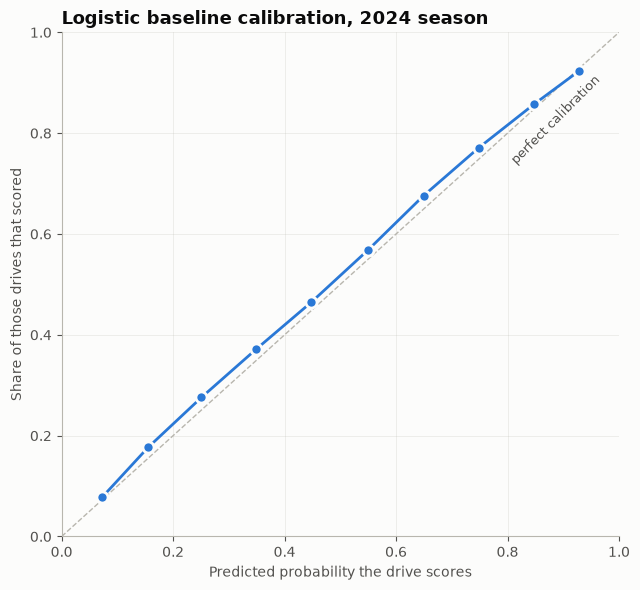

In [38]:
# chart style (same as the other notebooks)
BLUE = '#2a78d6'
SURFACE, INK, INK_2, MUTED = '#fcfcfb', '#0b0b0b', '#52514e', '#b8b6ae'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE,
    'axes.edgecolor': MUTED, 'axes.labelcolor': INK_2,
    'xtick.color': INK_2, 'ytick.color': INK_2,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlecolor': INK, 'axes.titlesize': 13, 'axes.titleweight': 'bold',
})

fig, ax = plt.subplots(figsize=(6.5, 6))

# perfect calibration: predicted = actual
ax.plot([0, 1], [0, 1], color=MUTED, linewidth=1, linestyle='--', zorder=1)
ax.text(0.97, 0.90, 'perfect calibration', color=INK_2, fontsize=9,
        ha='right', va='bottom', rotation=45, rotation_mode='anchor')

ax.plot(calib["mean_pred"], calib["actual_rate"], color=BLUE, linewidth=2,
        marker='o', markersize=8, markeredgecolor=SURFACE, markeredgewidth=2, zorder=2)

ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel('Predicted probability the drive scores')
ax.set_ylabel('Share of those drives that scored')
ax.set_title(f'Logistic baseline calibration, {valid_season} season', loc='left')
ax.grid(color=MUTED, alpha=0.3, linewidth=0.5)
plt.tight_layout()
plt.show()

In [39]:
# performance by field position: where is the model weakest?
zones = [0, 10, 20, 40, 60, 80, 99]
zone_labels = ['1-10', '11-20', '21-40', '41-60', '61-80', '81-99']

def zone_metrics(d):
    return pd.Series({
        "snaps":       len(d),
        "actual_rate": d[target].mean(),
        "mean_pred":   d["pred"].mean(),
        "log_loss":    log_loss(d[target], d["pred"], labels=[0, 1]),
        "brier":       brier_score_loss(d[target], d["pred"]),
    })

by_zone = (
    valid.assign(pred=y_prob,
                 yards_to_goal_zone=pd.cut(valid["yards_to_goal"], zones, labels=zone_labels))
    .groupby("yards_to_goal_zone", observed=True)[[target, "pred"]]
    .apply(zone_metrics)
)
by_zone["gap"] = by_zone["actual_rate"] - by_zone["mean_pred"]
by_zone.round(3)

,snaps,actual_rate,mean_pred,log_loss,brier,gap
yards_to_goal_zone,,,,,,
1-10,8411.0,0.855,0.856,0.390,0.118,-0.001
11-20,8778.0,0.790,0.748,0.493,0.158,0.043
21-40,22663.0,0.648,0.615,0.613,0.212,0.033
41-60,30508.0,0.443,0.442,0.647,0.228,0.001
61-80,41007.0,0.305,0.283,0.583,0.199,0.022
81-99,9367.0,0.216,0.177,0.486,0.158,0.038


## Gradient boosting + calibration

The baseline had two problems: it missed by 3-4 points at some field positions (logistic regression can only fit straight lines), and it ran ~2 points low everywhere (2024 drives scored more often than 2014-2023 drives).

- **Gradient boosting** learns curves and interactions (3rd-and-1 at midfield vs. at the 15). `monotonic_cst` keeps "closer to the goal" from ever lowering the probability.
- **No `early_stopping=True`:** it holds out a *random* 10% of training snaps, so snaps from the same drive land on both sides and the held-out score keeps improving while the model overfits. Instead, the number of iterations is chosen on 2024 games.
- **Platt calibration** (a one-feature logistic regression on the model's log-odds) corrects the level shift. It beat isotonic calibration here.
- 2024 is split **by game** into a *select* half (choose iterations, fit the calibrator) and an *eval* half (report honest numbers). 2025 stays untouched.

In [40]:
# split the validation season by game: half to select/calibrate, half to evaluate
rng = np.random.default_rng(42)
valid_games = valid["game_id"].unique()
select_games = rng.choice(valid_games, size=len(valid_games) // 2, replace=False)

is_select = valid["game_id"].isin(select_games).to_numpy()
is_eval = ~is_select
print(f"select half: {is_select.sum():,} snaps   eval half: {is_eval.sum():,} snaps")

select half: 59,999 snaps   eval half: 60,735 snaps


In [41]:
# fit long once, then find the iteration where select-half log loss bottoms out
gb_params = dict(
    learning_rate=0.05,
    max_leaf_nodes=31,
    early_stopping=False,                 # see note above: its random holdout leaks
    monotonic_cst={"yards_to_goal": -1},  # closer to the goal never lowers the probability
    random_state=42,
)
gb_long = HistGradientBoostingClassifier(max_iter=600, **gb_params).fit(X_train, y_train)

curve = pd.DataFrame(
    [(i, log_loss(y_valid[is_select], p[is_select, 1]))
     for i, p in enumerate(gb_long.staged_predict_proba(X_valid), start=1) if i % 25 == 0],
    columns=["iteration", "select_log_loss"],
)
best_iter = int(curve.loc[curve["select_log_loss"].idxmin(), "iteration"])
print(f"best iteration: {best_iter}")
curve.set_index("iteration").T.round(4)

best iteration: 200


iteration,25,50,75,100,125,150,175,200,225,250,...,375,400,425,450,475,500,525,550,575,600
select_log_loss,0.5886,0.5693,0.5627,0.5604,0.5593,0.5589,0.5589,0.5588,0.5589,0.5589,...,0.5591,0.559,0.5592,0.5592,0.5594,0.5595,0.5596,0.5598,0.5599,0.5599


In [42]:
# refit at the chosen size, then calibrate on the select half
gb = HistGradientBoostingClassifier(max_iter=best_iter, **gb_params).fit(X_train, y_train)

def to_logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)

gb_raw = gb.predict_proba(X_valid)[:, 1]
platt = LogisticRegression().fit(to_logit(gb_raw[is_select]), y_valid[is_select])

def predict_scoring_prob(X):
    """Final model: gradient boosting + Platt calibration."""
    return platt.predict_proba(to_logit(gb.predict_proba(X)[:, 1]))[:, 1]

final_prob = predict_scoring_prob(X_valid)

In [43]:
# compare all models on the eval half only (nothing below was fit on it)
y_eval = y_valid[is_eval]
comparison = pd.DataFrame([
    evaluate("naive (training rate)",  y_eval, np.full(is_eval.sum(), y_train.mean())),
    evaluate("logistic baseline",      y_eval, y_prob[is_eval]),
    evaluate("gradient boosting",      y_eval, gb_raw[is_eval]),
    evaluate("gb + Platt (final)",     y_eval, final_prob[is_eval]),
]).set_index("model")
comparison["brier_skill"] = 1 - comparison["brier"] / comparison.loc["naive (training rate)", "brier"]
comparison.round(4)

,log_loss,brier,auc,mean_pred,actual_rate,brier_skill
model,,,,,,
naive (training rate),0.6935,0.2502,0.5000,0.4543,0.4793,0.0000
logistic baseline,0.5781,0.1975,0.7637,0.4528,0.4793,0.2108
gradient boosting,0.5629,0.1917,0.7785,0.4525,0.4793,0.2339
gb + Platt (final),0.5614,0.1910,0.7785,0.4668,0.4793,0.2364


In [44]:
# field position and down: actual vs. predicted, baseline vs. final (eval half)
ev = valid[is_eval].assign(
    baseline=y_prob[is_eval],
    final=final_prob[is_eval],
    yards_to_goal_zone=pd.cut(valid.loc[is_eval, "yards_to_goal"], zones, labels=zone_labels),
)

def gaps(by):
    t = ev.groupby(by, observed=True).agg(
        snaps=(target, "size"), actual=(target, "mean"),
        baseline=("baseline", "mean"), final=("final", "mean"))
    t["gap_baseline"] = t["actual"] - t["baseline"]   # + = predicted too low
    t["gap_final"] = t["actual"] - t["final"]
    return t.round(3)

display(gaps("yards_to_goal_zone"))
display(gaps("down"))

,snaps,actual,baseline,final,gap_baseline,gap_final
yards_to_goal_zone,,,,,,
1-10,4391,0.859,0.855,0.861,0.004,-0.002
11-20,4392,0.801,0.749,0.793,0.052,0.008
21-40,11478,0.650,0.617,0.637,0.033,0.013
41-60,15326,0.449,0.440,0.428,0.008,0.021
61-80,20427,0.314,0.284,0.302,0.031,0.013
81-99,4721,0.225,0.176,0.223,0.049,0.002


,snaps,actual,baseline,final,gap_baseline,gap_final
down,,,,,,
1,26891,0.521,0.497,0.509,0.024,0.012
2,19718,0.482,0.453,0.467,0.029,0.015
3,12325,0.401,0.371,0.387,0.030,0.015
4,1801,0.362,0.348,0.380,0.014,-0.018


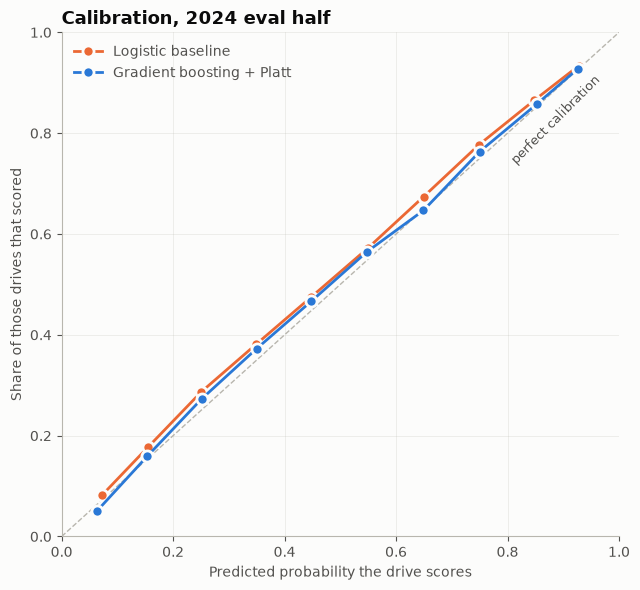

In [45]:
# calibration: baseline vs. final model (eval half)
ORANGE = '#eb6834'

def calib_points(prob, y):
    d = pd.DataFrame({"pred": prob, "actual": y.to_numpy()})
    d["bin"] = pd.cut(d["pred"], np.linspace(0, 1, 11), include_lowest=True)
    return d.groupby("bin", observed=True).agg(mean_pred=("pred", "mean"), actual_rate=("actual", "mean"))

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot([0, 1], [0, 1], color=MUTED, linewidth=1, linestyle='--', zorder=1)
ax.text(0.97, 0.90, 'perfect calibration', color=INK_2, fontsize=9,
        ha='right', va='bottom', rotation=45, rotation_mode='anchor')

for prob, color, label in [(y_prob[is_eval], ORANGE, 'Logistic baseline'),
                           (final_prob[is_eval], BLUE, 'Gradient boosting + Platt')]:
    pts = calib_points(prob, y_eval)
    ax.plot(pts["mean_pred"], pts["actual_rate"], color=color, linewidth=2, label=label,
            marker='o', markersize=8, markeredgecolor=SURFACE, markeredgewidth=2, zorder=2)

ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel('Predicted probability the drive scores')
ax.set_ylabel('Share of those drives that scored')
ax.set_title(f'Calibration, {valid_season} eval half', loc='left')
ax.legend(frameon=False, loc='upper left', labelcolor=INK_2)
ax.grid(color=MUTED, alpha=0.3, linewidth=0.5)
plt.tight_layout()
plt.show()

In [46]:
# save the final model: both pieces plus the exact feature order the live script must use
model_dir = ROOT / "models"
model_dir.mkdir(exist_ok=True)
joblib.dump(
    {"gb": gb, "platt": platt, "feature_columns": feature_columns,
     "trained_on": list(train_seasons), "calibrated_on": valid_season},
    model_dir / "drive_scoring.joblib",
)
print("saved", model_dir / "drive_scoring.joblib")

saved c:\Users\Owner\projects\cfb-project\models\drive_scoring.joblib
